# Comparação entre dois modelos gratuitos do OpenRouter

**Aluno:** Vitor de Moura Nascimento (RM 553806)
**Turma:** 4ESPS

## Objetivo

O objetivo desta atividade é enviar o mesmo prompt para dois modelos marcados como gratuitos no catálogo do OpenRouter e comparar as respostas. A comparação usa as evidências registradas durante a execução: horário de cada chamada, provedor que atendeu, quantidade de tokens, tempo de resposta e o próprio texto das respostas.

O notebook segue esta ordem:

0. Configuração do ambiente
1. Catálogo de modelos gratuitos
2. Escolha dos modelos
3. Prompt e parâmetros
4. Limites da conta
5. Execução
6. Evidências da execução
7. Métricas
8. Análise comparativa
9. Decisões tomadas
10. Limitações
11. Verificação de segurança
12. Conclusão

Para executar, é preciso configurar a variável `OPENROUTER_API_KEY` (no terminal ou em um arquivo `.env` na pasta do projeto) e rodar todas as células em ordem. As instruções completas estão no `README.md`.

## 0. Configuração do ambiente

A chave da API não aparece em nenhum lugar do notebook. Ela é lida da variável de ambiente `OPENROUTER_API_KEY` ou do arquivo `.env`, que está no `.gitignore` e fica fora do zip da entrega. Se nenhum dos dois existir, o código tenta os Secrets do Google Colab e, por último, pede a chave com `getpass`, que não mostra o valor digitado.

O valor da chave nunca é impresso. As mensagens de erro também passam por uma função que remove qualquer texto parecido com uma chave antes de exibir ou salvar. Para registro, são salvas a versão do Python e das bibliotecas, sem nome de usuário nem nome da máquina.

In [1]:
import json
import os
import platform
import textwrap
from datetime import datetime, timezone
from getpass import getpass
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display

from comparador import analise, seguranca
from comparador import openrouter as orc

PASTA_RESULTADOS = Path("resultados")
PASTA_RESULTADOS.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)

In [2]:
# A chave vem da variável de ambiente ou do arquivo .env (no Colab, dos Secrets).
# Se não for encontrada, o getpass pede a chave sem mostrar o que foi digitado.
try:
    CHAVE = orc.obter_chave()
except RuntimeError as motivo:
    print(motivo)
    print("Tentando os Secrets do Colab ou a digitação da chave...")
    try:
        from google.colab import userdata  # só existe no Colab
        os.environ[seguranca.NOME_VARIAVEL_CHAVE] = userdata.get("OPENROUTER_API_KEY")
    except Exception:
        os.environ[seguranca.NOME_VARIAVEL_CHAVE] = getpass("Cole a OPENROUTER_API_KEY: ").strip()
    CHAVE = orc.obter_chave(permitir_dotenv=False)

print("Chave carregada (o valor não é exibido).")

Chave carregada (o valor não é exibido).


In [3]:
AMBIENTE = {
    "execucao_inicio_utc": orc.agora_utc(),
    "python": platform.python_version(),
    "sistema_operacional": platform.system(),
    "bibliotecas": {"requests": requests.__version__, "pandas": pd.__version__,
                    "matplotlib": matplotlib.__version__, "numpy": np.__version__},
    "endpoint_api": orc.BASE_URL,
}
(PASTA_RESULTADOS / "ambiente.json").write_text(json.dumps(AMBIENTE, ensure_ascii=False, indent=2), encoding="utf-8")
AMBIENTE

{'execucao_inicio_utc': '2026-10-27T22:35:04+00:00',
 'python': '3.14.0',
 'sistema_operacional': 'Windows',
 'bibliotecas': {'requests': '2.34.2',
  'pandas': '2.3.3',
  'matplotlib': '3.11.2',
  'numpy': '2.3.4'},
 'endpoint_api': 'https://openrouter.ai/api/v1'}

## 1. Catálogo de modelos gratuitos

A lista de modelos vem do endpoint público `GET /api/v1/models`. Essa consulta não precisa de autenticação, então a chave não é enviada.

Foram considerados gratuitos os modelos com a marcação `:free` no id ou com todos os preços do catálogo iguais a zero. Também foi exigido que o modelo receba texto e responda apenas com texto. Esse filtro foi ajustado depois da primeira execução: dois modelos do Google (`lyria-3-clip-preview` e `lyria-3-pro-preview`) apareceram como gratuitos porque o preço por token era zero, mas eles cobram por requisição e geram música. Olhar só o preço por token não era suficiente.

A lista filtrada é salva com data e hora em `resultados/catalogo_gratuitos.json`. Esse arquivo comprova que os modelos usados estavam gratuitos no momento da execução.

In [4]:
CATALOGO = orc.listar_modelos()
GRATUITOS = orc.filtrar_gratuitos(CATALOGO)
caminho = orc.salvar_catalogo(GRATUITOS, len(CATALOGO), PASTA_RESULTADOS)
print(f"{len(CATALOGO)} modelos no catálogo, {len(GRATUITOS)} gratuitos de texto.")
print(f"Lista salva em {caminho} às {orc.agora_utc()} (UTC).")

pd.DataFrame([{
    "id": m["id"],
    "contexto": m["contexto"],
    "entrada": m["entrada"],
    "aceita temperature": "temperature" in m["parametros_suportados"],
    "aceita max_tokens": "max_tokens" in m["parametros_suportados"],
    "raciocínio": "reasoning" in m["parametros_suportados"],
    "publicado em": m["criado_em"],
} for m in GRATUITOS])

464 modelos no catálogo, 17 gratuitos de texto.
Lista salva em resultados\catalogo_gratuitos.json às 2026-10-27T22:35:05+00:00 (UTC).


,id,contexto,entrada,aceita temperature,aceita max_tokens,raciocínio,publicado em
0,cohere/north-mini-code:free,256000,text,True,True,True,2026-06-17
1,dots-studio/dots-3-note-preview:free,512000,text+image,True,True,True,2026-08-14
2,google/gemma-4-26b-a4b-it:free,262144,image+text+video,True,True,True,2026-04-03
3,google/gemma-4-31b-it:free,262144,image+text+video,True,True,True,2026-04-02
4,liquid/lfm-2.5-2.6b:free,65536,text,True,True,True,2026-08-11
5,nvidia/nemotron-3-nano-omni-30b-a3b-reasoning:free,256000,text+audio+image+video,True,True,True,2026-04-28
6,nvidia/nemotron-3-ultra-550b-a55b:free,1000000,text,True,True,True,2026-06-04
7,nvidia/nemotron-3.5-content-safety:free,128000,text+image,True,True,True,2026-06-04
8,nvidia/nemotron-3.5-lightning:free,1000000,text,True,True,True,2026-08-11
9,nvidia/nemotron-3.5-super-vl:free,1000000,text+image+video,True,True,True,2026-10-15


## 2. Escolha dos modelos

Os dois modelos foram escolhidos com estes critérios:

1. estar gratuito no catálogo consultado na hora da execução, e não em listas de terceiros;
2. ser de fornecedores diferentes, para a comparação ser mais interessante;
3. ser um modelo de uso geral. O roteador `openrouter/free` ficou de fora porque pode escolher um modelo diferente a cada chamada, e também ficaram de fora os modelos de moderação e segurança;
4. aceitar os parâmetros `temperature` e `max_tokens`, para que os dois rodem nas mesmas condições.

A primeira versão da lista `PREFERIDOS` foi montada a partir de uma lista pública de modelos gratuitos consultada em 26/10/2026, com o Gemma 4 31B (Google) e o Nemotron 3 Super (NVIDIA). Na execução de 27/10, o Nemotron 3 Super já não estava no catálogo, e a escolha automática completou o par com o Inkling Small (Thinking Machines). Essa execução falhou em todas as chamadas. O Gemma 4 31B recebeu erro 429 porque o provedor estava sobrecarregado, e o Inkling Small recebeu erro 403 porque só é liberado para aplicativos de agentes cadastrados no OpenRouter. Os detalhes estão na seção 10.

Por isso a lista foi refeita com base nas descrições do catálogo, priorizando modelos de uso geral. O Nemotron 3 Ultra (NVIDIA) e o Dots 3 Note (Dots Studio) ficaram como modelos A e B, e os outros da lista servem de reserva, nessa ordem. Os modelos descritos no catálogo como feitos para agentes de programação (North Mini Code, Laguna e Flint) ficam no fim da fila de reservas, porque o prompt é de uso geral.

In [5]:
PREFERIDOS = [
    "nvidia/nemotron-3-ultra-550b-a55b:free",
    "dots-studio/dots-3-note-preview:free",
    "google/gemma-4-31b-it:free",  # reserva: o provedor estava sobrecarregado na primeira execução
    "xingchen-agi/xing4.0-29b-a4b:free",
    "google/gemma-4-26b-a4b-it:free",
]

ESCOLHA = orc.escolher_modelos(GRATUITOS, PREFERIDOS, n=2)
MODELOS = ESCOLHA["escolhidos"]

for justificativa in ESCOLHA["justificativas"]:
    print("-", justificativa)
print("\nModelo A:", MODELOS[0])
print("Modelo B:", MODELOS[1])
print("Reservas (usadas só se um modelo estiver indisponível na 1ª rodada):", ESCOLHA["reservas"][:4])

- nvidia/nemotron-3-ultra-550b-a55b:free: preferido e gratuito no catálogo consultado.
- dots-studio/dots-3-note-preview:free: preferido e gratuito no catálogo consultado.
- google/gemma-4-31b-it:free: preferido, fica na lista de reservas.
- xingchen-agi/xing4.0-29b-a4b:free: preferido, fica na lista de reservas.
- google/gemma-4-26b-a4b-it:free: preferido, fica na lista de reservas.

Modelo A: nvidia/nemotron-3-ultra-550b-a55b:free
Modelo B: dots-studio/dots-3-note-preview:free
Reservas (usadas só se um modelo estiver indisponível na 1ª rodada): ['google/gemma-4-31b-it:free', 'xingchen-agi/xing4.0-29b-a4b:free', 'google/gemma-4-26b-a4b-it:free', 'thinkingmachines/inkling-small:free']


## 3. Prompt e parâmetros

O prompt foi montado para ter partes que podem ser conferidas de forma objetiva, além da leitura das respostas:

| Parte | O que é pedido | Como conferir |
|---|---|---|
| Conceito | explicar overfitting em até 3 frases e citar um sinal prático | contagem de frases e leitura |
| Cálculo | troco de uma compra (4 x R\$ 2,50 + 3 x R\$ 12,00, paga com R\$ 100,00) | a resposta certa é R\$ 54,00 |
| Limitações | listar exatamente 2 limitações de modelos gratuitos via API | contagem de itens e leitura |
| Formato | três seções na ordem pedida, até 220 palavras, em português | regras automáticas |

Os dois modelos recebem exatamente a mesma entrada: uma única mensagem do tipo `user`, sem mensagem de sistema, porque alguns modelos tratam o papel `system` de forma diferente.

Os parâmetros foram fixados em `temperature = 0.3`, para reduzir a variação entre as respostas, e `max_tokens = 10000`. O limite começou em 1500 e foi aumentado duas vezes. Primeiro passou para 4000, porque o catálogo mostrou que quase todos os modelos gratuitos fazem raciocínio antes de responder, e esses tokens contam no mesmo limite. Depois passou para 10000, porque na segunda execução completa o Dots 3 Note gastou os 4000 tokens só no raciocínio, contando as palavras uma a uma para respeitar o limite de 220, e as três respostas vieram vazias. O Nemotron 3 Ultra usou cerca de 1000 tokens por resposta, então o limite maior não muda nada para ele.

Cada modelo é executado 3 vezes. Assim dá para observar se as respostas são consistentes, sem passar do limite diário de requisições gratuitas. O prompt não contém dados pessoais, porque os provedores de modelos gratuitos podem guardar as entradas ou usá-las para treino.

In [6]:
PROMPT = """Responda em português do Brasil, com no máximo 220 palavras no total, usando exatamente as três seções abaixo, nesta ordem, cada uma iniciada pelo seu título em uma linha própria:

### Conceito
Explique, em até 3 frases e para um estudante iniciante, o que é overfitting (sobreajuste) em aprendizado de máquina e cite um sinal prático de que ele está ocorrendo.

### Cálculo
Uma papelaria vende canetas a R$ 2,50 cada e cadernos a R$ 12,00 cada. Ana comprou 4 canetas e 3 cadernos e pagou com uma nota de R$ 100,00. Mostre o cálculo passo a passo e informe o troco.

### Limitações
Liste exatamente 2 limitações de usar modelos de linguagem gratuitos por meio de uma API, em tópicos curtos."""

MENSAGENS = [{"role": "user", "content": PROMPT}]
PARAMETROS = {"temperature": 0.3, "max_tokens": 10000}
REPETICOES = 3

# Gabarito usado nas verificações automáticas da seção 7
TAREFA = {
    "titulos": ["Conceito", "Cálculo", "Limitações"],
    "secao_conceito": "Conceito", "secao_calculo": "Cálculo", "secao_lista": "Limitações",
    "max_palavras": 220, "max_frases_conceito": 3, "itens_lista": 2,
    "resposta_calculo": 100 - (4 * 2.50 + 3 * 12.00),
}
HASH_PROMPT = orc.sha256(json.dumps(MENSAGENS, ensure_ascii=False, sort_keys=True))
(PASTA_RESULTADOS / "prompt.txt").write_text(PROMPT, encoding="utf-8")

print(f"Troco esperado: R$ {TAREFA['resposta_calculo']:.2f}".replace(".", ","))
print("SHA-256 do prompt:", HASH_PROMPT)
print("Parâmetros:", PARAMETROS, "| repetições por modelo:", REPETICOES, "\n")

POR_ID = {m["id"]: m for m in GRATUITOS}
for m in MODELOS:
    faltam = [p for p in PARAMETROS if p not in POR_ID[m]["parametros_suportados"]]
    print(f"{m}: " + ("aceita todos os parâmetros" if not faltam
                      else f"não declara {', '.join(faltam)}, o provedor pode ignorar"))

Troco esperado: R$ 54,00
SHA-256 do prompt: ec778eb7d165b0e6a85b563e51432f8e13116259b26891f522661f39db41ef23
Parâmetros: {'temperature': 0.3, 'max_tokens': 10000} | repetições por modelo: 3 

nvidia/nemotron-3-ultra-550b-a55b:free: aceita todos os parâmetros
dots-studio/dots-3-note-preview:free: aceita todos os parâmetros


## 4. Limites da conta

Segundo a documentação do OpenRouter, os modelos `:free` têm limite de 20 requisições por minuto e de 50 por dia para contas que compraram menos de 10 créditos (1000 por dia acima disso). Uma conta com saldo negativo recebe erro 402 mesmo nos modelos gratuitos.

A célula abaixo consulta a cota restante pelo endpoint `GET /api/v1/key`. Desse retorno são guardados só os campos de uso. O campo `label`, que mostra parte da chave, é descartado.

In [7]:
LIMITES = orc.consultar_limites(CHAVE)
(PASTA_RESULTADOS / "limites_conta.json").write_text(json.dumps(LIMITES, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(LIMITES, ensure_ascii=False, indent=2))

CHAMADAS_PREVISTAS = REPETICOES * len(MODELOS)
restantes = (LIMITES.get("free_model_daily_requests") or {}).get("remaining")
print(f"\nChamadas previstas: {CHAMADAS_PREVISTAS} (fora eventuais novas tentativas por erro temporário)")
if isinstance(restantes, (int, float)) and restantes < CHAMADAS_PREVISTAS + 4:
    print("Atenção: cota diária baixa. Reduza REPETICOES ou execute depois da virada do dia (UTC).")
elif restantes is not None:
    print(f"Cota diária restante: {restantes}, suficiente para a execução.")

{
  "consultado_em_utc": "2026-10-27T22:35:05+00:00",
  "is_free_tier": true,
  "free_model_daily_requests": {
    "used": 6,
    "limit": 50,
    "remaining": 44
  }
}

Chamadas previstas: 6 (fora eventuais novas tentativas por erro temporário)
Cota diária restante: 44, suficiente para a execução.


## 5. Execução

A execução segue estas regras:

- o mesmo prompt e os mesmos parâmetros são enviados aos dois modelos;
- a ordem alterna a cada rodada (A e depois B na primeira, B e depois A na segunda, A e depois B na terceira), para que nenhum modelo seja sempre favorecido por horário ou pela fila do provedor;
- há uma pausa de 4 segundos entre as chamadas, para ficar abaixo do limite de 20 por minuto;
- erros temporários (429, erros 5xx e tempo esgotado) são tentados de novo com uma espera que aumenta a cada tentativa. Erros que não se resolvem repetindo (400, 401, 402, 403 e 404) não são repetidos, para não gastar a cota;
- se um modelo estiver indisponível na primeira rodada, ele é trocado por um modelo reserva de outro fornecedor, e a troca fica registrada. Conta como indisponível o modelo bloqueado pela política de privacidade da conta, o modelo restrito a certos aplicativos (erro 403), o modelo cujo provedor continua sobrecarregado depois das novas tentativas (erro 429 "upstream") e o modelo que não responde dentro do tempo limite;
- cada chamada é gravada na hora em `resultados/execucoes.jsonl`, então o registro não se perde se a execução parar no meio. Uma execução anterior é movida para `resultados/historico/`.

A variável `REUTILIZAR_EXECUCAO_SALVA` permite carregar uma execução já gravada sem fazer novas chamadas, o que é útil para refazer só a análise.

In [8]:
REUTILIZAR_EXECUCAO_SALVA = False  # True carrega resultados/execucoes.jsonl sem chamar a API

ARQ_EXECUCOES = PASTA_RESULTADOS / "execucoes.jsonl"
ARQ_DECISOES = PASTA_RESULTADOS / "decisoes_automaticas.json"

if REUTILIZAR_EXECUCAO_SALVA and ARQ_EXECUCOES.exists():
    REGISTROS = [json.loads(l) for l in ARQ_EXECUCOES.read_text(encoding="utf-8").splitlines() if l.strip()]
    salvo = json.loads(ARQ_DECISOES.read_text(encoding="utf-8")) if ARQ_DECISOES.exists() else {}
    DECISOES_AUTO = salvo.get("decisoes", [])
    MODELOS = salvo.get("modelos_finais", MODELOS)
    print(f"{len(REGISTROS)} registros carregados de {ARQ_EXECUCOES}, sem novas chamadas.")
else:
    if ARQ_EXECUCOES.exists():  # guarda a execução anterior como histórico, com a data em que ela começou
        primeira = ARQ_EXECUCOES.read_text(encoding="utf-8").splitlines()[:1]
        marca = (json.loads(primeira[0])["inicio_utc"][:19].replace("-", "").replace(":", "") if primeira
                 else f"{datetime.now(timezone.utc):%Y%m%dT%H%M%S}")
        (PASTA_RESULTADOS / "historico").mkdir(exist_ok=True)
        ARQ_EXECUCOES.rename(PASTA_RESULTADOS / "historico" / f"execucoes_{marca}Z.jsonl")
    resultado = orc.rodar_comparacao(
        CHAVE, MODELOS, MENSAGENS, PARAMETROS, REPETICOES, ARQ_EXECUCOES,
        reservas=ESCOLHA["reservas"], substituir_se_indisponivel=True, pausa_s=4.0,
    )
    REGISTROS = resultado["registros"]
    DECISOES_AUTO = resultado["decisoes"]
    MODELOS = resultado["modelos_finais"]
    ARQ_DECISOES.write_text(json.dumps({"modelos_finais": MODELOS, "decisoes": DECISOES_AUTO},
                                       ensure_ascii=False, indent=2), encoding="utf-8")

print(f"\nChamadas registradas: {len(REGISTROS)}")
print(f"Modelos comparados: A = {MODELOS[0]} | B = {MODELOS[1]}")

[rodada 1] nvidia/nemotron-3-ultra-550b-a55b:free: ok em 20.076s (1495 tokens, provedor Nvidia)
[rodada 1] dots-studio/dots-3-note-preview:free: ok em 82.988s (8891 tokens, provedor AtlasCloud)
[rodada 2] dots-studio/dots-3-note-preview:free: ok em 61.611s (6677 tokens, provedor AtlasCloud)
[rodada 2] nvidia/nemotron-3-ultra-550b-a55b:free: ok em 27.37s (1053 tokens, provedor Nvidia)
[rodada 3] nvidia/nemotron-3-ultra-550b-a55b:free: ok em 18.548s (1090 tokens, provedor Nvidia)
[rodada 3] dots-studio/dots-3-note-preview:free: ok em 58.312s (5653 tokens, provedor AtlasCloud)

Chamadas registradas: 6
Modelos comparados: A = nvidia/nemotron-3-ultra-550b-a55b:free | B = dots-studio/dots-3-note-preview:free


## 6. Evidências da execução

Para cada chamada ficam registrados o horário (UTC), o modelo pedido e o modelo que respondeu, o provedor que atendeu (o OpenRouter pode mandar o mesmo modelo para provedores diferentes), o id da geração no OpenRouter, o status HTTP, o número de tentativas, o tempo de resposta, o motivo de término, a quantidade de tokens e o hash SHA-256 do prompt. O hash serve para conferir que o prompt foi exatamente o mesmo em todas as chamadas. Os registros completos ficam em `resultados/execucoes.jsonl`.

In [9]:
DF = analise.tabela_execucoes(REGISTROS, TAREFA)
COLUNAS_EVIDENCIA = ["rodada", "modelo", "inicio_utc", "sucesso", "status_http", "tentativas", "latencia_s",
                     "provedor", "finish_reason", "tokens_prompt", "tokens_completion", "tokens_raciocinio",
                     "geracao_id", "erro_tipo", "erros_contornados"]
display(DF[COLUNAS_EVIDENCIA])

print("Mesmo prompt em todas as chamadas (hash conferido):", {r["prompt_sha256"] for r in REGISTROS} == {HASH_PROMPT})
print("Mesmos parâmetros em todas as chamadas:", all(r["parametros"] == PARAMETROS for r in REGISTROS))
print("Modelo pedido -> modelo informado na resposta:")
for pedido, respondido in sorted({(r["modelo_solicitado"], r.get("modelo_respondido"))
                                  for r in REGISTROS if r["sucesso"]}):
    print(f"   {pedido} -> {respondido}")

,rodada,modelo,inicio_utc,sucesso,status_http,tentativas,latencia_s,provedor,finish_reason,tokens_prompt,tokens_completion,tokens_raciocinio,geracao_id,erro_tipo,erros_contornados
0,1,nvidia/nemotron-3-ultra-550b-a55b:free,2026-10-27T22:35:05+00:00,True,200,1,20.076,Nvidia,stop,217,1495,903,gen-1793140506-YlR0byeJfeMnHaht1Ueh,None,None
1,1,dots-studio/dots-3-note-preview:free,2026-10-27T22:35:29+00:00,True,200,1,82.988,AtlasCloud,stop,234,8891,6960,gen-1793140530-CLTpSoXUgyauj5jdXOjb,None,None
2,2,dots-studio/dots-3-note-preview:free,2026-10-27T22:36:56+00:00,True,200,1,61.611,AtlasCloud,stop,234,6677,5143,gen-1793140617-nlKUHJiir6mlqj8QQLp5,None,None
3,2,nvidia/nemotron-3-ultra-550b-a55b:free,2026-10-27T22:38:02+00:00,True,200,1,27.370,Nvidia,stop,217,1053,645,gen-1793140682-PRInfPrn4qJJ6BOHQfTd,None,None
4,3,nvidia/nemotron-3-ultra-550b-a55b:free,2026-10-27T22:38:33+00:00,True,200,1,18.548,Nvidia,stop,217,1090,713,gen-1793140714-m7qiiRTT3dW9awh7qL8w,None,None
5,3,dots-studio/dots-3-note-preview:free,2026-10-27T22:38:56+00:00,True,200,1,58.312,AtlasCloud,stop,234,5653,4571,gen-1793140736-dX1pCUvXUD7l2qRUsGJh,None,None


Mesmo prompt em todas as chamadas (hash conferido): True
Mesmos parâmetros em todas as chamadas: True
Modelo pedido -> modelo informado na resposta:
   dots-studio/dots-3-note-preview:free -> dots-studio/dots-3-note-preview:free
   nvidia/nemotron-3-ultra-550b-a55b:free -> nvidia/nemotron-3-ultra-550b-a55b:free


### Respostas completas

As respostas de cada rodada aparecem abaixo, na ordem em que foram obtidas. O mesmo conteúdo fica salvo em `resultados/respostas.md`.

In [10]:
def mostrar(texto, largura=110):
    for linha in (texto or "").splitlines():
        print(textwrap.fill(linha, largura, subsequent_indent="   ") if linha.strip() else "")

partes_md = ["# Respostas obtidas\n", f"Prompt (SHA-256 `{HASH_PROMPT[:16]}...`):\n\n```text\n{PROMPT}\n```\n"]
for rodada in sorted({r["rodada"] for r in REGISTROS}):
    print("=" * 110 + f"\nRODADA {rodada}")
    partes_md.append(f"\n## Rodada {rodada}\n")
    for r in [x for x in REGISTROS if x["rodada"] == rodada]:
        if r["sucesso"]:
            cabecalho = (f"{r['modelo_solicitado']} | {r['inicio_utc']} | provedor: {r.get('provedor')} | "
                         f"{r.get('latencia_s')} s | {r.get('tokens_completion')} tokens | geração: {r.get('geracao_id')}")
        else:
            cabecalho = (f"{r['modelo_solicitado']} | {r['inicio_utc']} | HTTP {r.get('status_http')} "
                         f"após {r.get('tentativas')} tentativa(s)")
        print("-" * 110 + f"\n{cabecalho}\n" + "-" * 110)
        if r["sucesso"]:
            corpo = r.get("resposta") or "(resposta vazia)"
            mostrar(corpo)
            if r.get("alerta"):
                print(f"\nAviso: {r['alerta']}")
        else:
            corpo = f"FALHOU ({r.get('erro_tipo')}): {r.get('erro_mensagem')}"
            print(corpo)
        partes_md.append(f"\n### {r['modelo_solicitado']}\n\n_{cabecalho}_\n\n```text\n{corpo}\n```\n")

(PASTA_RESULTADOS / "respostas.md").write_text(seguranca.mascarar("\n".join(partes_md)), encoding="utf-8")

RODADA 1
--------------------------------------------------------------------------------------------------------------
nvidia/nemotron-3-ultra-550b-a55b:free | 2026-10-27T22:35:05+00:00 | provedor: Nvidia | 20.076 s | 1495 tokens | geração: gen-1793140506-YlR0byeJfeMnHaht1Ueh
--------------------------------------------------------------------------------------------------------------
### Conceito
Overfitting ocorre quando o modelo aprende detalhes e ruído dos dados de treino em vez do padrão geral. Um
   sinal prático é a acurácia muito alta no treino e bem menor no teste.

### Cálculo
4 canetas × R$2,50 = R$10,00. 3 cadernos × R$12,00 = R$36,00. Total = R$46,00. Troco = R$100,00 – R$46,00 =
   R$54,00.

### Limitações
- Limite de requisições por minuto.
- Menor precisão e suporte comparado a versões pagas.
--------------------------------------------------------------------------------------------------------------
dots-studio/dots-3-note-preview:free | 2026-10-27T22:35:29+00:00 | p

5179

## 7. Métricas

As respostas passam por seis verificações automáticas:

| Verificação | Regra | O que mostra |
|---|---|---|
| `formato_ok` | as três seções aparecem como títulos, na ordem pedida | se o modelo seguiu a estrutura |
| `limite_palavras_ok` | até 220 palavras | se respeitou o tamanho |
| `idioma_pt_ok` | predominam palavras do português | se respondeu no idioma pedido |
| `calculo_ok` | a seção Cálculo contém o valor 54 (R\$ 54,00) | acerto de um resultado conhecido |
| `lista_ok` | exatamente 2 itens na seção Limitações | se respeitou a quantidade pedida |
| `conceito_frases_ok` | a seção Conceito tem de 1 a 3 frases | se respeitou o limite de frases |

A pontuação objetiva é a fração dessas seis regras que a resposta cumpriu (de 0 a 1). Uma resposta vazia não cumpre nenhuma regra e fica com 0. Além disso, são medidos o tempo de resposta, a quantidade de tokens de saída e a consistência entre as rodadas.

Alguns cuidados na leitura desses números:

- o tempo de resposta inclui a rede e a fila do provedor, não só o processamento do modelo;
- cada modelo usa um tokenizador próprio, então a quantidade de tokens não é comparável diretamente, e por isso também foram contadas as palavras;
- a consistência é a semelhança entre os textos das rodadas de um mesmo modelo (1 significa respostas idênticas);
- as regras são heurísticas simples, com o código em `comparador/analise.py`, e a tabela por resposta abaixo permite conferir cada caso.

In [11]:
COLUNAS_METRICAS = ["rodada", "modelo", "resposta_vazia", *analise.CRITERIOS, "pontuacao_objetiva", "palavras",
                    "itens_na_lista", "frases_no_conceito", "secoes_encontradas"]
display(DF[DF["sucesso"]][[c for c in COLUNAS_METRICAS if c in DF.columns]])

,rodada,modelo,resposta_vazia,formato_ok,limite_palavras_ok,idioma_pt_ok,calculo_ok,lista_ok,conceito_frases_ok,pontuacao_objetiva,palavras,itens_na_lista,frases_no_conceito,secoes_encontradas
0,1,nvidia/nemotron-3-ultra-550b-a55b:free,False,True,True,True,True,True,True,1.0,81,2,2,Conceito > Cálculo > Limitações
1,1,dots-studio/dots-3-note-preview:free,False,True,True,True,True,True,True,1.0,112,2,3,Conceito > Cálculo > Limitações
2,2,dots-studio/dots-3-note-preview:free,False,True,True,True,True,True,True,1.0,99,2,2,Conceito > Cálculo > Limitações
3,2,nvidia/nemotron-3-ultra-550b-a55b:free,False,True,True,True,True,True,True,1.0,85,2,2,Conceito > Cálculo > Limitações
4,3,nvidia/nemotron-3-ultra-550b-a55b:free,False,True,True,True,True,True,True,1.0,85,2,2,Conceito > Cálculo > Limitações
5,3,dots-studio/dots-3-note-preview:free,False,True,True,True,True,True,True,1.0,96,2,2,Conceito > Cálculo > Limitações


In [12]:
COMP = analise.tabela_comparativa(DF[DF["modelo"].isin(MODELOS)], REGISTROS).reindex(MODELOS)
COMP.to_csv(PASTA_RESULTADOS / "comparativo.csv", encoding="utf-8")
DF.to_csv(PASTA_RESULTADOS / "execucoes_tabela.csv", index=False, encoding="utf-8")

substituidos = sorted(set(DF["modelo"]) - set(MODELOS))
if substituidos:
    print("Modelos substituídos (aparecem nas evidências, mas não no comparativo):", substituidos)
display(COMP.T.rename(columns={MODELOS[0]: f"A: {MODELOS[0]}", MODELOS[1]: f"B: {MODELOS[1]}"}))

modelo,A: nvidia/nemotron-3-ultra-550b-a55b:free,B: dots-studio/dots-3-note-preview:free
chamadas,3,3
sucessos,3,3
respostas_vazias,0,0
tentativas_extras,0,0
provedores,Nvidia,AtlasCloud
latencia_media_s,22.0,67.64
latencia_desvio_s,4.71,13.4
tokens_saida_medio,1212.7,7073.7
tokens_raciocinio_medio,753.7,5558.0
palavras_medio,83.7,102.3


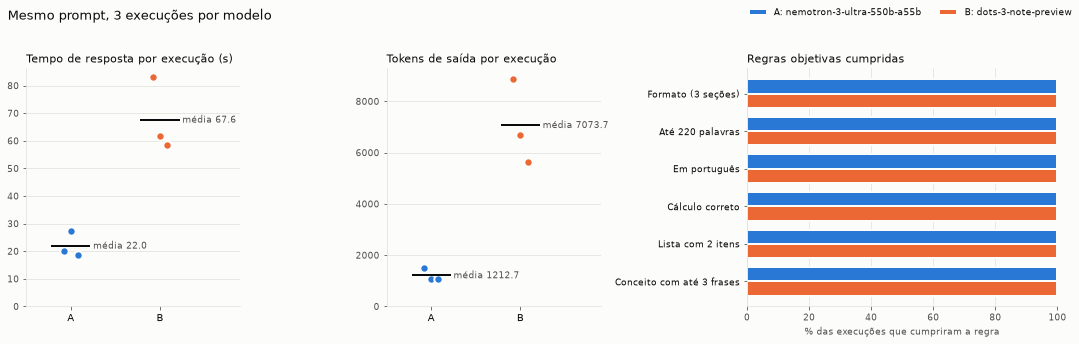

In [13]:
CORES = ["#2a78d6", "#eb6834"]  # azul para A e laranja para B (cores distinguíveis para daltonismo)
TINTA, TINTA_2, GRADE, FUNDO = "#0b0b0b", "#52514e", "#e4e3de", "#fcfcfb"
NOMES = [m.split("/")[-1].replace(":free", "") for m in MODELOS]
OK = DF[DF["sucesso"] & DF["modelo"].isin(MODELOS)]

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.8), facecolor=FUNDO, gridspec_kw={"width_ratios": [1, 1, 1.45]})
for ax in eixos:
    ax.set_facecolor(FUNDO)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(GRADE)
    ax.tick_params(colors=TINTA_2, labelsize=9)
    ax.set_axisbelow(True)

# Gráficos 1 e 2: cada ponto é uma execução e o traço preto é a média
for ax, coluna, titulo in [(eixos[0], "latencia_s", "Tempo de resposta por execução (s)"),
                           (eixos[1], "tokens_completion", "Tokens de saída por execução")]:
    ax.grid(axis="y", color=GRADE, linewidth=0.8)
    for i, (modelo, cor) in enumerate(zip(MODELOS, CORES)):
        valores = OK.loc[OK["modelo"] == modelo, coluna].dropna().astype(float)
        if valores.empty:
            continue
        deslocamentos = np.linspace(-0.08, 0.08, len(valores)) if len(valores) > 1 else [0.0]
        ax.scatter(i + np.asarray(deslocamentos), valores, s=70, color=cor, edgecolor=FUNDO, linewidth=2, zorder=3)
        ax.hlines(valores.mean(), i - 0.22, i + 0.22, color=TINTA, linewidth=2, zorder=4)
        ax.annotate(f"média {valores.mean():.1f}", (i + 0.25, valores.mean()), va="center", fontsize=9, color=TINTA_2)
    ax.set_xticks(range(len(MODELOS)), ["A", "B"], color=TINTA, fontsize=10)  # nomes completos na legenda
    ax.set_xlim(-0.5, len(MODELOS) - 0.1)
    ax.set_ylim(bottom=0)
    ax.set_title(titulo, loc="left", fontsize=11, color=TINTA)

# Gráfico 3: porcentagem das execuções que cumpriram cada regra
ROTULOS = {"formato_ok": "Formato (3 seções)", "limite_palavras_ok": "Até 220 palavras",
           "idioma_pt_ok": "Em português", "calculo_ok": "Cálculo correto",
           "lista_ok": "Lista com 2 itens", "conceito_frases_ok": "Conceito com até 3 frases"}
ax = eixos[2]
y, altura = np.arange(len(analise.CRITERIOS)), 0.38
for i, (modelo, cor) in enumerate(zip(MODELOS, CORES)):
    sub = OK[OK["modelo"] == modelo]
    taxas = [100 * sub[c].eq(True).mean() if (c in sub and len(sub)) else 0 for c in analise.CRITERIOS]
    ax.barh(y + (i - 0.5) * altura, taxas, height=altura, color=cor, edgecolor=FUNDO, linewidth=2,
            label=f"{'AB'[i]}: {NOMES[i]}")
ax.set_yticks(y, [ROTULOS[c] for c in analise.CRITERIOS], color=TINTA, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.grid(axis="x", color=GRADE, linewidth=0.8)
ax.set_xlabel("% das execuções que cumpriram a regra", color=TINTA_2, fontsize=9)
ax.set_title("Regras objetivas cumpridas", loc="left", fontsize=11, color=TINTA)

fig.suptitle(f"Mesmo prompt, {REPETICOES} execuções por modelo", x=0.01, ha="left", fontsize=13, color=TINTA)
fig.legend(*ax.get_legend_handles_labels(), loc="upper right", ncol=2, frameon=False, fontsize=9, labelcolor=TINTA)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(PASTA_RESULTADOS / "comparativo.png", dpi=150, facecolor=FUNDO)
plt.show()

## 8. Análise comparativa

### 8.1 Resumo dos números

O texto abaixo é montado automaticamente a partir da tabela comparativa da seção 7.

In [14]:
display(Markdown(analise.resumo_automatico(COMP)))

Foram comparados os modelos A (nvidia/nemotron-3-ultra-550b-a55b:free) e B (dots-studio/dots-3-note-preview:free), com o mesmo prompt e os mesmos parâmetros. O modelo A respondeu 3 de 3 chamadas e o B respondeu 3 de 3, com 0 e 0 tentativas extras, respectivamente. O tempo médio de resposta foi de 22.0 s para A e 67.64 s para B (o modelo A foi mais rápido nesta amostra). Nas regras objetivas (escala de 0 a 1), A teve 1.0 e B teve 1.0, então houve empate. O cálculo do troco foi acertado em 3/3 execuções por A e em 3/3 por B. Como a amostra é pequena, diferenças pequenas não devem ser tratadas como conclusivas.

### 8.2 Análise das respostas

A versão final da comparação foi feita em 27/10/2026, entre 22:35 e 22:40 (UTC), com o Nemotron 3 Ultra (modelo A, atendido pela própria NVIDIA) e o Dots 3 Note (modelo B, atendido pela AtlasCloud). Os dois modelos responderam às 3 rodadas sem erro e cumpriram as 6 regras objetivas em todas elas, então a pontuação objetiva empatou em 1,0. As diferenças apareceram na leitura das respostas, no tempo de resposta e no uso de tokens.

Sobre o conceito, os dois explicaram overfitting corretamente e citaram um sinal prático válido. O Nemotron foi mais direto, sempre em 2 frases, comparando a acurácia de treino com a de teste (na rodada 2, com a de validação). Na rodada 3, porém, o sinal prático virou uma frase solta ("Sinal prático: acurácia muito alta no treino, mas baixa no teste."). O Dots foi um pouco mais didático e, na rodada 1, acrescentou a causa do problema ("Isso acontece quando o modelo é muito complexo para a quantidade de dados"), o que ajuda um estudante iniciante.

No cálculo, os dois chegaram a R\$ 54,00 nas 3 rodadas. O Dots mostrou todas as etapas, inclusive a soma (R\$ 10,00 + R\$ 36,00 = R\$ 46,00) e a subtração, apesar de ter escrito os valores sem o "R\$" na rodada 2. O Nemotron foi mais resumido: nas rodadas 1 e 3 escreveu apenas "Total = R\$46,00", sem mostrar a soma, e na rodada 2 passou direto do valor pago para o troco, sem mostrar a subtração. Como o prompt pedia o cálculo passo a passo, o Dots atendeu melhor esse ponto.

Nas limitações ficou a maior diferença de qualidade. O Nemotron citou limitações ligadas ao uso de modelos gratuitos por API: limite de requisições por minuto e cota diária (nas 3 rodadas), menor precisão e suporte em relação às versões pagas, falta de garantias de privacidade e mudanças de comportamento sem aviso. Essas limitações apareceram na prática durante este trabalho, com os erros 429, o modelo que saiu do catálogo e os provedores que podem guardar os dados. O Dots, na maior parte das vezes, citou limitações de modelos de linguagem em geral, como contexto limitado, vieses e dados desatualizados, que valeriam também para modelos pagos. Só na rodada 1 ele citou algo específico do uso gratuito ("Limites de uso e possíveis custos ocultos").

Quanto à consistência, o Nemotron deu respostas mais parecidas entre as rodadas, com similaridade de 0,597 contra 0,314 do Dots. O Dots variou mais a forma, por exemplo escrevendo o cálculo em texto corrido na rodada 2 e em linhas separadas nas outras. As respostas do Dots também começaram com duas linhas em branco, o que é só um detalhe visual.

A diferença mais clara foi no tempo e no uso de tokens. O Nemotron levou em média 22,0 s por resposta e gerou cerca de 1.213 tokens de saída, dos quais 754 de raciocínio. O Dots levou 67,6 s e gerou cerca de 7.074 tokens, dos quais 5.558 de raciocínio, ou seja, quase seis vezes mais tokens e três vezes mais tempo. Os registros da segunda execução, guardados em `resultados/historico`, mostram o motivo: no raciocínio, o Dots contava as palavras uma por uma para garantir o limite de 220 e, com `max_tokens = 4000`, não chegou a escrever a resposta em nenhuma das três rodadas. Mesmo com todo esse cuidado, as respostas finais dele ficaram com cerca de 102 palavras, bem abaixo do limite. Em um serviço pago esse comportamento custaria bem mais, e no gratuito ele deixa a resposta lenta.

Notas atribuídas a cada modelo (de 1 a 5):

| Critério | A: Nemotron 3 Ultra | B: Dots 3 Note | Evidência |
|---|---|---|---|
| Correção do conceito e do cálculo | 5 | 5 | Conceito correto e troco de R\$ 54,00 nas 3 rodadas dos dois |
| Clareza para um estudante iniciante | 4 | 5 | O Dots explicou também a causa do overfitting (rodada 1) |
| Cálculo passo a passo | 4 | 5 | O Nemotron não mostrou a soma (rodadas 1 e 3) nem a subtração (rodada 2) |
| Pertinência das limitações | 5 | 2 | O Nemotron citou cota, privacidade e mudanças sem aviso; o Dots citou limitações gerais de LLMs |
| Formato e restrições | 5 | 5 | 6 de 6 regras cumpridas nas 3 rodadas pelos dois |
| Consistência entre rodadas | 4 | 3 | Similaridade de 0,597 contra 0,314 |
| Tempo de resposta e uso de tokens | 5 | 2 | 22,0 s e 1.213 tokens contra 67,6 s e 7.074 tokens |
| Média | 4,6 | 3,9 | |

## 9. Decisões tomadas

| # | Decisão | Alternativa considerada | Motivo |
|---|---|---|---|
| 1 | Identificar os modelos gratuitos pelo catálogo oficial no momento da execução e salvar a lista com data | Usar uma lista fixa de modelos | A disponibilidade muda; o arquivo salvo comprova que os modelos estavam gratuitos naquele momento |
| 2 | Considerar gratuito só o modelo com `:free` no id ou com todos os preços zerados, e com saída apenas em texto | Olhar só o preço por token | Na primeira execução, os modelos Lyria apareceram como gratuitos sem ser |
| 3 | Escolher modelos de fornecedores diferentes, de uso geral, que aceitam `temperature` e `max_tokens` | Dois modelos do mesmo fornecedor ou o roteador `openrouter/free` | A comparação fica mais informativa, e o roteador troca de modelo a cada chamada |
| 4 | Completar a escolha automaticamente quando um modelo preferido sai do catálogo | Trocar os modelos manualmente | O Nemotron 3 Super saiu do catálogo entre 26/10 e 27/10 |
| 5 | Usar um prompt com partes verificáveis (cálculo com resposta conhecida, contagem de itens e de frases, formato) | Uma pergunta aberta | Permite métricas objetivas além da leitura |
| 6 | Enviar uma única mensagem `user`, sem `system` | Instruções em mensagem de sistema | Garante a mesma entrada para os dois modelos |
| 7 | `temperature = 0.3` e `max_tokens = 10000` para os dois | Padrão de cada modelo ou limites de 1500 e 4000 | Mesmas condições e pouca variação; o raciocínio dos modelos conta no limite de tokens |
| 8 | 3 repetições por modelo, em ordem alternada e com pausa de 4 s | Uma execução por modelo | Permite medir a consistência e reduz o efeito do horário e da fila, dentro dos limites gratuitos |
| 9 | Repetir só erros temporários e parar ao atingir o limite diário | Repetir qualquer erro | Evita gastar a cota gratuita |
| 10 | Trocar um modelo indisponível na 1ª rodada por um reserva de outro fornecedor | Encerrar a atividade | Modelos gratuitos podem estar fora do ar ou bloqueados pela política de dados da conta |
| 11 | Manter a chave só no ambiente ou no `.env`, sem imprimir, mascarada em erros e verificada antes do envio | Escrever a chave no código | Exigência de segurança da atividade |
| 12 | Tratar o erro 403 de acesso restrito como modelo indisponível e trocar por uma reserva | Classificar todo erro 403 como bloqueio por moderação | Na primeira execução completa, o Inkling Small recebeu 403 nas três rodadas ("only available on agentic harnesses") e o código antigo não fazia a troca |
| 13 | Trocar na 1ª rodada o modelo cujo provedor continua sobrecarregado depois das novas tentativas | Insistir no mesmo modelo | Na primeira execução completa, o Gemma 4 31B recebeu 429 ("rate-limited upstream") nas 12 tentativas |
| 14 | Priorizar modelos de uso geral (Nemotron 3 Ultra e Dots 3 Note) e deixar os de agentes de programação no fim da fila | Escolher pelo maior contexto | O prompt é de uso geral, e o critério de maior contexto levou a um modelo restrito |
| 15 | Limitar a 2 as tentativas quando o tempo de resposta esgota | 4 tentativas de até 180 s cada | Evita que um modelo lento prenda a execução por vários minutos |
| 16 | Aumentar `max_tokens` de 4000 para 10000 | Reduzir o raciocínio com o parâmetro `reasoning` | Na segunda execução completa, o Dots 3 Note usou os 4000 tokens raciocinando e entregou 3 respostas vazias. Aumentar o limite mantém o comportamento normal dos dois modelos |
| 17 | Avaliar resposta vazia como nota 0 em todas as regras | Ignorar a resposta vazia nas métricas | O modelo respondeu à chamada, mas não entregou o que foi pedido; ignorar esse caso esconderia a falha (e quebrava o cálculo da tabela comparativa) |

As decisões tomadas automaticamente durante esta execução (trocas de modelo ou interrupções) aparecem abaixo:

In [15]:
if DECISOES_AUTO:
    display(pd.DataFrame(DECISOES_AUTO))
else:
    print("Nenhuma: os dois modelos responderam e não foi preciso trocar ou interromper.")

Nenhuma: os dois modelos responderam e não foi preciso trocar ou interromper.


## 10. Limitações

| Limitação | Impacto | Como foi tratada |
|---|---|---|
| A lista de modelos gratuitos muda com frequência | A execução pode não ser reproduzível com os mesmos modelos | Lista salva com data, escolha automática com reservas e ids registrados |
| Limites de 20 requisições por minuto e 50 por dia sem créditos | Erros 429 ou execução interrompida | Pausa entre chamadas, novas tentativas com espera, consulta da cota antes e opção de reaproveitar a execução salva |
| O mesmo modelo pode ser atendido por provedores diferentes | O tempo e o comportamento podem variar entre chamadas | Provedor registrado em cada chamada |
| O tempo de resposta inclui rede e fila | Não mede só a velocidade do modelo | Várias execuções, com média e desvio padrão |
| Tokenizadores diferentes | A contagem de tokens não é comparável diretamente | Contagem de palavras como medida complementar |
| Modelos com raciocínio gastam tokens antes de responder | Resposta cortada ou vazia (aconteceu com o Dots 3 Note na segunda execução) | `max_tokens = 10000`, aviso automático, tokens de raciocínio registrados e resposta vazia avaliada como nota 0 |
| Amostra pequena (3 por modelo) e temperatura maior que zero | Diferenças pequenas não são conclusivas | Resultados tratados como indícios e consistência medida |
| Métricas baseadas em expressões regulares | Podem errar com formatos inesperados | Regras simples e tabela por resposta para conferência, além da leitura |
| A política de privacidade da conta pode bloquear alguns provedores gratuitos | Modelo indisponível (erro 404) | Troca por um reserva de outro fornecedor |
| Provedores gratuitos podem guardar as entradas ou treinar com elas | Risco de privacidade | Prompt sem dados pessoais ou confidenciais |
| Alguns modelos gratuitos só são liberados para aplicativos parceiros do OpenRouter | Erro 403 mesmo com o modelo no catálogo | Troca por um reserva na 1ª rodada |
| O provedor de um modelo gratuito muito usado pode ficar congestionado | Erro 429 em todas as tentativas | Troca por um reserva na 1ª rodada e registro da execução com falha em `resultados/historico` |

Execuções anteriores ficam guardadas em `resultados/historico`, com a data em que começaram. A tabela abaixo mostra cada chamada dessas execuções, com a mensagem de erro devolvida pelo servidor ou o aviso registrado sobre a resposta:

In [16]:
PASTA_HISTORICO = PASTA_RESULTADOS / "historico"
linhas_hist = []
for arq in sorted(PASTA_HISTORICO.glob("execucoes_*.jsonl")) if PASTA_HISTORICO.exists() else []:
    for linha in arq.read_text(encoding="utf-8").splitlines():
        if linha.strip():
            r = json.loads(linha)
            linhas_hist.append({"execução": arq.stem.replace("execucoes_", ""), "rodada": r.get("rodada"),
                                "modelo": r["modelo_solicitado"], "sucesso": r["sucesso"],
                                "status_http": r.get("status_http"), "tentativas": r.get("tentativas"),
                                "finish_reason": r.get("finish_reason"),
                                "observação": (r.get("erro_mensagem") or r.get("alerta") or "")[:110]})
if linhas_hist:
    display(pd.DataFrame(linhas_hist))
else:
    print("Nenhuma execução anterior guardada.")

,execução,rodada,modelo,sucesso,status_http,tentativas,finish_reason,observação
0,20261027T221823Z,1,google/gemma-4-31b-it:free,False,429,4,None,Provider returned error google/gemma-4-31b-it:free is te...
1,20261027T221823Z,1,thinkingmachines/inkling-small:free,False,403,1,None,thinkingmachines/inkling-small:free is only available on...
2,20261027T221823Z,2,thinkingmachines/inkling-small:free,False,403,1,None,thinkingmachines/inkling-small:free is only available on...
3,20261027T221823Z,2,google/gemma-4-31b-it:free,False,429,4,None,Provider returned error google/gemma-4-31b-it:free is te...
4,20261027T221823Z,3,google/gemma-4-31b-it:free,False,429,4,None,Provider returned error google/gemma-4-31b-it:free is te...
5,20261027T221823Z,3,thinkingmachines/inkling-small:free,False,403,1,None,thinkingmachines/inkling-small:free is only available on...
6,20261027T222645Z,1,nvidia/nemotron-3-ultra-550b-a55b:free,True,200,1,stop,
7,20261027T222645Z,1,dots-studio/dots-3-note-preview:free,True,200,1,length,resposta vazia (o raciocínio consumiu o limite de tokens)
8,20261027T222645Z,2,dots-studio/dots-3-note-preview:free,True,200,1,length,resposta vazia (o raciocínio consumiu o limite de tokens)
9,20261027T222645Z,2,nvidia/nemotron-3-ultra-550b-a55b:free,True,200,1,stop,


Limitações observadas na execução atual:

In [17]:
falhas = DF[~DF["sucesso"]]
print("Chamadas com falha:", len(falhas))
if len(falhas):
    display(falhas[["rodada", "modelo", "status_http", "erro_tipo"]])
print("Novas tentativas por erro temporário:", int((DF["tentativas"] - 1).clip(lower=0).sum()))
print("Respostas cortadas pelo limite de tokens:", int(DF["finish_reason"].eq("length").sum()))
alertas = [f"{r['modelo_solicitado']} (rodada {r['rodada']}): {r['alerta']}" for r in REGISTROS if r.get("alerta")]
print("Avisos sobre o conteúdo:", "; ".join(alertas) if alertas else "nenhum")
provedores = DF[DF["sucesso"]].groupby("modelo")["provedor"].nunique()
print("Provedores distintos por modelo:", provedores.to_dict())

Chamadas com falha: 0
Novas tentativas por erro temporário: 0
Respostas cortadas pelo limite de tokens: 0
Avisos sobre o conteúdo: nenhum
Provedores distintos por modelo: {'dots-studio/dots-3-note-preview:free': 1, 'nvidia/nemotron-3-ultra-550b-a55b:free': 1}


## 11. Verificação de segurança

Cuidados adotados com a chave e com os dados:

- a chave é lida do ambiente e nunca aparece nas células nem nas saídas;
- o catálogo é consultado sem enviar a chave, e da consulta de limites só são guardados os campos de uso;
- as mensagens de erro e os arquivos de evidência passam por uma função que remove chaves;
- o `ambiente.json` não tem nome de usuário nem da máquina, e o prompt não tem dados pessoais;
- o `.env` está no `.gitignore` e não entra no zip da entrega.

A célula abaixo verifica o projeto inteiro, incluindo este notebook como está salvo e a pasta `resultados`. Ela procura o valor exato da chave carregada, textos no formato de chave (`sk-or-...` e `Bearer ...`) e dados pessoais como e-mail, CPF e telefone. Antes de enviar, também é preciso rodar `python verificar_entrega.py --zip` no terminal, com o notebook salvo.

In [18]:
AMBIENTE["execucao_fim_utc"] = orc.agora_utc()
(PASTA_RESULTADOS / "ambiente.json").write_text(json.dumps(AMBIENTE, ensure_ascii=False, indent=2), encoding="utf-8")

VARREDURA = seguranca.varrer(".")
assert seguranca.imprimir_relatorio(VARREDURA), "Há possíveis segredos no projeto. Remova-os antes da entrega."

Arquivos verificados: 22
[OK] Nenhuma chave de API encontrada.

[AVISO] 1 item(ns) para revisão manual:
   - .env  [arquivo .env]  não inclua este arquivo na entrega


## 12. Conclusão

Considerando as evidências das seções 6 a 8, o Nemotron 3 Ultra se saiu melhor nesta tarefa. Os dois modelos acertaram o conteúdo e cumpriram todas as regras objetivas, mas o Nemotron respondeu cerca de três vezes mais rápido, usou quase seis vezes menos tokens, foi mais consistente entre as rodadas e apontou limitações realmente ligadas ao uso de modelos gratuitos por API. O Dots 3 Note teve pontos positivos, como a explicação um pouco mais didática do conceito e o cálculo mais detalhado, mas o raciocínio muito longo deixou as respostas lentas e, com o limite de 4000 tokens, ele não entregou nenhuma resposta.

Esses resultados têm ressalvas. A amostra é pequena (3 execuções por modelo), o tempo medido inclui a rede e a fila de cada provedor, e as métricas automáticas são heurísticas, por isso as respostas também foram analisadas pela leitura. Além disso, a própria atividade mostrou como o uso de modelos gratuitos é instável: em poucos dias um modelo saiu do catálogo, o Gemma 4 31B ficou indisponível por sobrecarga do provedor e o Inkling Small recusou as chamadas por ser restrito a alguns aplicativos. Foram necessárias três execuções e alguns ajustes no código até chegar a uma comparação válida, e todas elas ficaram registradas em `resultados`.

Em uma situação real parecida, com perguntas curtas e necessidade de resposta rápida, o Nemotron 3 Ultra seria a escolha. O Dots 3 Note só faria sentido se o tempo de resposta não importasse e houvesse um limite de tokens bem folgado. Em qualquer caso, para um uso contínuo seria importante ter um modelo reserva e tratar os erros de disponibilidade, como foi feito neste trabalho.